# Classificação com Redes Neurais — Fórmula 1: previsão de Top 10

**Projeto:** Inteligência Artificial — aplicação de redes neurais em um problema real de classificação com dados tabulares.

**Pergunta de negócio:** dado o grid de largada, a equipe, o circuito e o histórico recente de desempenho na temporada, o piloto termina a corrida entre os 10 primeiros colocados (faixa de pontuação)?

**Fonte dos dados:** [jolpica-f1](https://github.com/jolpica/jolpica-f1) (sucessor open-source da Ergast API), consolidado em `dataframes/results.csv` (1950–2026, uma linha por piloto por corrida) e `dataframes/races.csv` (calendário e circuitos), atualizado até o GP do Brasil de 2026 (rodada 20).


## 1. Carregamento e união das tabelas

Unimos `results.csv` (um piloto por corrida) com `races.csv` (contexto do circuito: localização, latitude/longitude) pela chave `season` + `round`.


In [1]:
import pandas as pd
import numpy as np

results = pd.read_csv('dataframes/results.csv')
races = pd.read_csv('dataframes/races.csv')

df = results.merge(
    races[['season', 'round', 'circuit_id', 'country', 'lat', 'long']],
    on=['season', 'round'], how='left'
)

print(f"Linhas: {len(df)} | Colunas: {df.shape[1]}")
df.head(3)


Linhas: 26313 | Colunas: 28


,season,round,race_name,date,driver_id,driver_code,driver_number,driver_name,driver_nationality,driver_dob,...,status,time_text,time_millis,fastest_lap_rank,fastest_lap,fastest_lap_speed,circuit_id,country,lat,long
0,1950,1,British Grand Prix,1950-05-13,farina,NaN,2.0,Nino Farina,Italian,1906-10-30,...,Finished,2:13:23.600,8003600.0,NaN,NaN,NaN,silverstone,UK,52.0786,-1.01694
1,1950,1,British Grand Prix,1950-05-13,fagioli,NaN,3.0,Luigi Fagioli,Italian,1898-06-09,...,Finished,+2.600,8006200.0,NaN,NaN,NaN,silverstone,UK,52.0786,-1.01694
2,1950,1,British Grand Prix,1950-05-13,reg_parnell,NaN,4.0,Reg Parnell,British,1911-07-02,...,Finished,+52.000,8055600.0,NaN,NaN,NaN,silverstone,UK,52.0786,-1.01694


## 2. Definição do alvo (target)

Classificação binária: `target_top10 = 1` se o piloto terminou entre os 10 primeiros colocados (faixa que pontua nas regras atuais), `0` caso contrário.

**Observação importante:** o sistema de pontos da F1 mudou ao longo da história (por muito tempo só os 6 primeiros pontuavam; o top 10 pontuando é regra desde 2010). Por isso tratamos o alvo como **"terminar entre os 10 primeiros colocados"** — um conceito válido em qualquer época — e não literalmente "pontuar", que dependeria da regra vigente em cada ano.


Proporção Top10: 0.447


<Axes: title={'center': 'Distribuição do alvo (0 = fora do Top10, 1 = Top10)'}, xlabel='target_top10'>

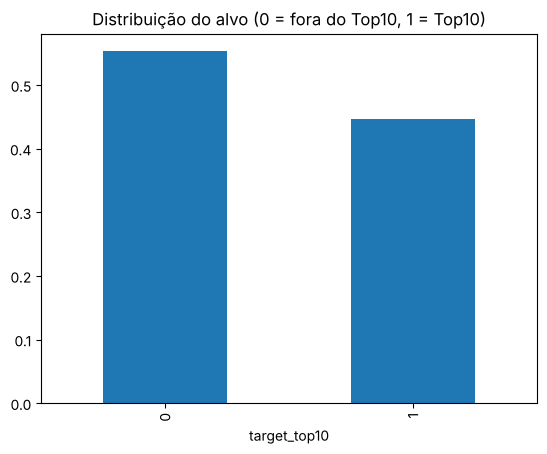

In [2]:
df['target_top10'] = (df['position'] <= 10).astype(int)
print("Proporção Top10:", df['target_top10'].mean().round(3))
df['target_top10'].value_counts(normalize=True).plot(kind='bar', title='Distribuição do alvo (0 = fora do Top10, 1 = Top10)')


## 3. Engenharia de features (sem *data leakage*)

Usamos apenas informação disponível **antes** do resultado da corrida:

- `grid`: posição de largada (classificação/qualifying).
- `lat`, `long`: localização do circuito.
- `season`: temporada (captura evolução de regras/carros ao longo do tempo).
- `driver_avg_pos_season` e `constructor_avg_points_season`: médias móveis calculadas **só com corridas anteriores da mesma temporada** (via `shift()` antes do `expanding().mean()`), evitando que o modelo "veja o futuro".

> **Correção (09/11/2026):** a primeira versão calculava essas médias com `groupby(...).apply(...).reset_index(drop=True)`. Esse padrão devolve os valores na ordem dos *grupos*, não das linhas — em ~99% das linhas a média ficava com outro piloto/equipe (a correlação da feature com a posição real era 0,04, contra 0,41 do valor correto). Na prática o modelo era treinado sem informação real de forma e passava a depender quase só do grid. A versão atual usa `groupby(...).transform(...)`, que mantém o alinhamento. A correção melhorou o modelo como um todo e, principalmente, os casos de pilotos rápidos largando fora de posição (punições, classificatório ruim).
- `constructor_id`, `circuit_id`, `driver_nationality`: variáveis categóricas.

Não usamos `points`, `status`, `laps`, `time_millis` etc. — essas colunas só existem **depois** da corrida acontecer e configurariam vazamento de dados (o modelo estaria "colando" a resposta).


In [3]:
df = df.sort_values(['season', 'round']).reset_index(drop=True)

# transform (e não apply + reset_index) mantém cada média alinhada à sua linha
df['driver_avg_pos_season'] = (
    df.groupby(['season', 'driver_id'])['position']
      .transform(lambda s: s.shift().expanding().mean())
)
df['constructor_avg_points_season'] = (
    df.groupby(['season', 'constructor_id'])['points']
      .transform(lambda s: s.shift().expanding().mean())
)

# na 1a corrida da temporada ainda não há histórico: usa a mediana geral
df['driver_avg_pos_season'] = df['driver_avg_pos_season'].fillna(df['position'].median())
df['constructor_avg_points_season'] = df['constructor_avg_points_season'].fillna(df['points'].median())

numeric_features = ['grid', 'lat', 'long', 'season', 'driver_avg_pos_season', 'constructor_avg_points_season']
categorical_features = ['constructor_id', 'circuit_id', 'driver_nationality']
feature_cols = numeric_features + categorical_features

model_df = df[feature_cols + ['target_top10']].dropna(subset=numeric_features)
print("Linhas após limpeza:", len(model_df))


Linhas após limpeza: 26313


## 4. Divisão treino/teste (split temporal)

Em vez de um split aleatório, separamos por **tempo**: treino = temporadas até 2023, teste = 2024–2026 (nunca vistas). Isso simula o cenário real — prever corridas futuras a partir do histórico — e evita qualquer contaminação temporal entre treino e teste.


In [4]:
df_final = df.loc[model_df.index].copy()  # mantém a coluna season para o split

train_df = model_df[df_final['season'] <= 2023]
test_df = model_df[df_final['season'] >= 2024]

print(f"Treino: {len(train_df)} linhas (1950-2023) | Teste: {len(test_df)} linhas (2024-2026)")
print("Proporção Top10 no treino:", train_df['target_top10'].mean().round(3))
print("Proporção Top10 no teste: ", test_df['target_top10'].mean().round(3))


Treino: 24915 linhas (1950-2023) | Teste: 1398 linhas (2024-2026)
Proporção Top10 no treino: 0.445
Proporção Top10 no teste:  0.486


## 5. Pré-processamento

- **Numéricas:** padronização (`StandardScaler`) — necessário para redes neurais convergirem bem.
- **Categóricas:** one-hot encoding (`OneHotEncoder`, com `handle_unknown='ignore'` para lidar com equipes/circuitos novos que aparecem só no conjunto de teste, como a Cadillac F1 Team em 2026).


In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

X_train_raw = train_df[numeric_features + categorical_features]
y_train = train_df['target_top10'].values
X_test_raw = test_df[numeric_features + categorical_features]
y_test = test_df['target_top10'].values

preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), numeric_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features),
])

X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)
print("Shape treino:", X_train.shape, "| Shape teste:", X_test.shape)


Shape treino: (24915, 325) | Shape teste: (1398, 325)


## 6. Rede Neural (MLP)

Arquitetura simples: MLP com 3 camadas ocultas (64 → 32 → 16 neurônios, ReLU) e `Dropout` para regularização, saída com 1 neurônio `sigmoid` (classificação binária). Otimizador Adam, perda `binary_crossentropy`, e `EarlyStopping` monitorando o AUC de validação para evitar overfitting.


In [6]:
import os, sys
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'   # silencia logs internos do TensorFlow (nível Python)

# o TensorFlow também escreve logs de inicialização (oneDNN/CUDA) direto no
# stderr do processo, abaixo do controle do Python -- silenciamos temporariamente
# o file descriptor durante o import para manter a saída do notebook limpa.
_stderr_fd = sys.stderr.fileno()
_saved_stderr = os.dup(_stderr_fd)
_devnull = os.open(os.devnull, os.O_WRONLY)
os.dup2(_devnull, _stderr_fd)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

os.dup2(_saved_stderr, _stderr_fd)
os.close(_devnull); os.close(_saved_stderr)

tf.random.set_seed(42)
np.random.seed(42)

n_features = X_train.shape[1]

model = keras.Sequential([
    layers.Input(shape=(n_features,)),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(16, activation='relu'),
    layers.Dense(1, activation='sigmoid'),
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy', keras.metrics.AUC(name='auc')]
)

model.summary()


I0000 00:00:1794226871.312759     198 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794226873.371519     198 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │        20,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,489 (91.75 KB)

 Trainable params: 23,489 (91.75 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_auc', mode='max', patience=8, restore_best_weights=True
)

# a 1a chamada a uma op do TensorFlow verifica a disponibilidade de GPU e escreve
# um aviso de "cuInit failed" no stderr de baixo nível -- silenciado pelo mesmo motivo acima.
_stderr_fd = sys.stderr.fileno()
_saved_stderr = os.dup(_stderr_fd)
_devnull = os.open(os.devnull, os.O_WRONLY)
os.dup2(_devnull, _stderr_fd)

# validation_split usa os últimos 15% do array (já ordenado por temporada/rodada)
# como validação -- ou seja, as temporadas mais recentes DENTRO do treino.
history = model.fit(
    X_train, y_train,
    validation_split=0.15,
    epochs=100,
    batch_size=64,
    callbacks=[early_stop],
    verbose=2,
)

os.dup2(_saved_stderr, _stderr_fd)
os.close(_devnull); os.close(_saved_stderr)


Epoch 1/100


331/331 - 2s - 6ms/step - accuracy: 0.6541 - auc: 0.7076 - loss: 0.6179 - val_accuracy: 0.7600 - val_auc: 0.8361 - val_loss: 0.5136


Epoch 2/100


331/331 - 1s - 2ms/step - accuracy: 0.6725 - auc: 0.7324 - loss: 0.5983 - val_accuracy: 0.7627 - val_auc: 0.8366 - val_loss: 0.5074


Epoch 3/100


331/331 - 1s - 2ms/step - accuracy: 0.6776 - auc: 0.7394 - loss: 0.5913 - val_accuracy: 0.7624 - val_auc: 0.8345 - val_loss: 0.5103


... (10 outputs left out)

Epoch 9/100


331/331 - 1s - 3ms/step - accuracy: 0.6966 - auc: 0.7654 - loss: 0.5683 - val_accuracy: 0.7630 - val_auc: 0.8291 - val_loss: 0.5108


Epoch 10/100


331/331 - 1s - 3ms/step - accuracy: 0.6984 - auc: 0.7681 - loss: 0.5665 - val_accuracy: 0.7614 - val_auc: 0.8274 - val_loss: 0.5140


## 7. Avaliação no conjunto de teste (temporadas 2024–2026, nunca vistas pelo modelo)

In [8]:
from sklearn.metrics import (classification_report, confusion_matrix,
                              roc_auc_score, roc_curve, f1_score, accuracy_score)

y_pred_proba = model.predict(X_test).ravel()
y_pred = (y_pred_proba >= 0.5).astype(int)

acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_pred_proba)

print(f"Acurácia: {acc:.3f}")
print(f"F1-score: {f1:.3f}")
print(f"AUC-ROC:  {auc:.3f}")
print()
print(classification_report(y_test, y_pred, target_names=['Fora do Top10', 'Top10']))


 1/44 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step

44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 

44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


Acurácia: 0.790
F1-score: 0.785
AUC-ROC:  0.863

               precision    recall  f1-score   support

Fora do Top10       0.80      0.79      0.79       718
        Top10       0.78      0.79      0.78       680

     accuracy                           0.79      1398
    macro avg       0.79      0.79      0.79      1398
 weighted avg       0.79      0.79      0.79      1398



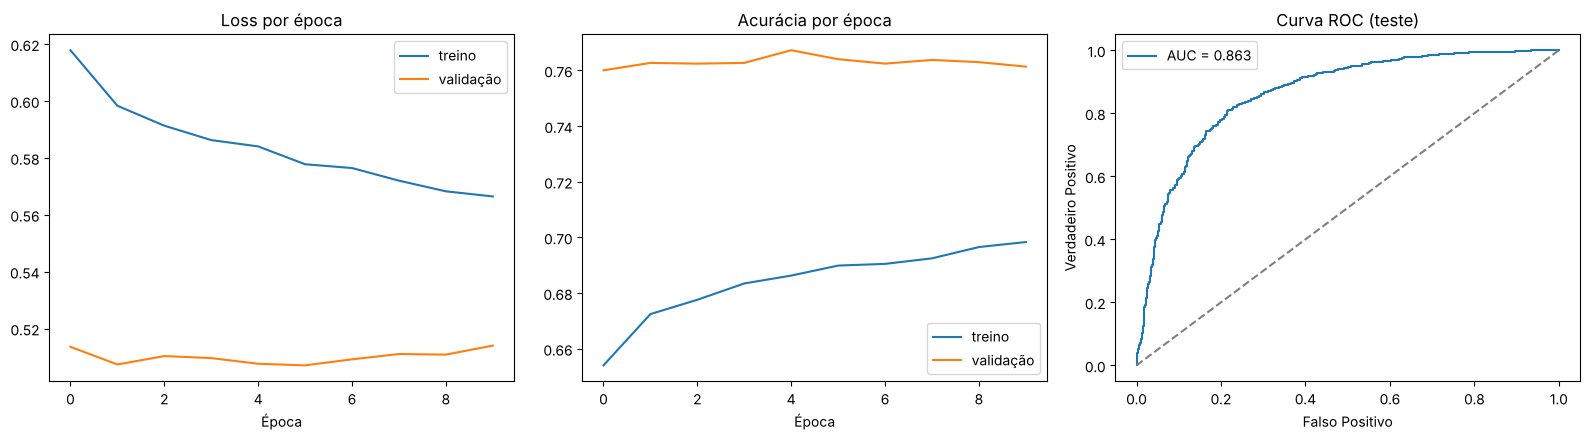

In [9]:
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].plot(history.history['loss'], label='treino')
axes[0].plot(history.history['val_loss'], label='validação')
axes[0].set_title('Loss por época'); axes[0].set_xlabel('Época'); axes[0].legend()

axes[1].plot(history.history['accuracy'], label='treino')
axes[1].plot(history.history['val_accuracy'], label='validação')
axes[1].set_title('Acurácia por época'); axes[1].set_xlabel('Época'); axes[1].legend()

axes[2].plot(fpr, tpr, label=f'AUC = {auc:.3f}')
axes[2].plot([0, 1], [0, 1], linestyle='--', color='gray')
axes[2].set_title('Curva ROC (teste)'); axes[2].set_xlabel('Falso Positivo'); axes[2].set_ylabel('Verdadeiro Positivo')
axes[2].legend()

plt.tight_layout()
plt.show()


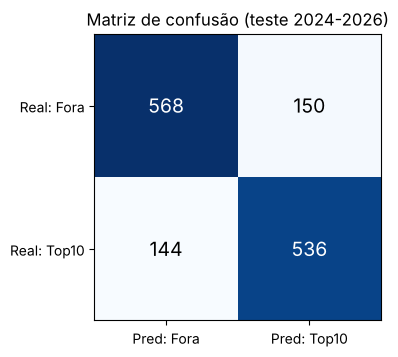

In [10]:
plt.figure(figsize=(4, 4))
plt.imshow(cm, cmap='Blues')
plt.title('Matriz de confusão (teste 2024-2026)')
plt.xticks([0, 1], ['Pred: Fora', 'Pred: Top10'])
plt.yticks([0, 1], ['Real: Fora', 'Real: Top10'])
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center',
                  color='white' if cm[i, j] > cm.max()/2 else 'black', fontsize=14)
plt.tight_layout()
plt.show()


## 8. Conclusões

O modelo atingiu **acurácia ~79%**, **F1-score ~0.78** e **AUC-ROC ~0.86** em corridas de 2024-2026 nunca vistas durante o treino — um resultado sólido para um MLP relativamente simples. O grid de largada por si só já é um forte preditor, mas a rede também aprende padrões de equipe, circuito e forma do piloto/equipe na temporada.

Com as médias da temporada calculadas corretamente (ver correção na seção 3), o modelo passou a distinguir um piloto lento largando atrás de um piloto rápido largando atrás por punição. Na versão com o bug, a acurácia era 77,5% (AUC 0,853). Nas rodadas 13–20 de 2026 com o grid real, a acurácia foi de 76,1% para 84,1%, e no GP do Brasil (cinco punições de motor) o Top 10 previsto passou de 7 para 10 acertos.

**Possíveis melhorias futuras:**
- Incluir dados de qualifying (tempo de volta, não só posição) e pit stops, que não estavam nesta versão do dataset.
- Testar outras arquiteturas (mais camadas, regularização L2, tuning de hiperparâmetros com Keras Tuner).
- Avaliar separadamente por era (ex.: só 2010+, quando a regra do Top10 pontuando é a mesma de hoje) para um recorte mais homogêneo.
- Comparar com baselines simples (regressão logística, árvore de decisão) para quantificar o ganho real da rede neural.


## 9. Aplicando o modelo: previsão para as próximas corridas de 2026

Como demonstração prática, o modelo treinado é usado para estimar a probabilidade de Top 10 nas próximas corridas do calendário, com a forma da temporada 2026 até a última corrida disputada (detectada automaticamente nos dados).

A lógica fica em `prever_proximas_corridas.py` — o mesmo script usado para atualizar as previsões a cada corrida sem retreinar o modelo. Ele reproduz o pré-processamento deste notebook, monta a escalação atual de cada equipe (2 pilotos com mais largadas nas últimas 5 rodadas, mais trocas confirmadas em `SUBSTITUICOES`) e usa o grid real quando o classificatório já aconteceu (`GRID_REAL`).

**Limitação importante:** a posição de largada (`grid`) só é conhecida depois do classificatório. Para corridas sem classificatório, o script usa como *proxy* a média de grid de cada piloto na temporada — ou seja, é uma estimativa de tendência, não uma previsão do resultado do fim de semana.


In [11]:
# salva o modelo treinado nesta execução e roda o script de previsão com ele
model.save('f1_top10_model.keras')

import prever_proximas_corridas as previsor
season_eval, result = previsor.main()


Última corrida disputada: rodada 20 — Brazilian Grand Prix



=== Las Vegas Grand Prix (rodada 21, 2026-11-22) ===
 1. antonelli        mercedes       90.0%  (forma recente  90.3%)  <- Top10 previsto
 2. russell          mercedes       89.2%  (forma recente  87.5%)  <- Top10 previsto
 3. hamilton         ferrari        87.7%  (forma recente  87.2%)  <- Top10 previsto
 4. leclerc          ferrari        87.3%  (forma recente  86.9%)  <- Top10 previsto
 5. norris           mclaren        81.8%  (forma recente  81.9%)  <- Top10 previsto
 6. max_verstappen   red_bull       81.4%  (forma recente  81.6%)  <- Top10 previsto
 7. hadjar           red_bull       80.9%  (forma recente  80.8%)  <- Top10 previsto
 8. piastri          mclaren        79.7%  (forma recente  78.2%)  <- Top10 previsto
 9. lawson           rb             59.2%  (forma recente  59.9%)  <- Top10 previsto
10. arvid_lindblad   rb             53.2%  (forma recente  46.7%)  <- Top10 previsto
11. gasly            alpine         45.0%  (forma recente  45.4%)
12. colapinto        alpine   

In [12]:
# Top 10 previsto por corrida (ordenado por probabilidade de Top 10, não por posição de chegada)
for rnd, sub in result.groupby('round'):
    sub = sub.sort_values('prob_top10', ascending=False).head(10)
    print(f"\n=== {sub['race_name'].iloc[0]} (rodada {rnd}) ===")
    for i, (_, row) in enumerate(sub.iterrows(), 1):
        print(f"{i:2d}. {row['driver_id']:<18s} ({row['constructor_id']:<12s}) prob. Top10: {row['prob_top10']:.1%}")



=== Las Vegas Grand Prix (rodada 21) ===
 1. antonelli          (mercedes    ) prob. Top10: 90.0%
 2. russell            (mercedes    ) prob. Top10: 89.2%
 3. hamilton           (ferrari     ) prob. Top10: 87.7%
 4. leclerc            (ferrari     ) prob. Top10: 87.3%
 5. norris             (mclaren     ) prob. Top10: 81.8%
 6. max_verstappen     (red_bull    ) prob. Top10: 81.4%
 7. hadjar             (red_bull    ) prob. Top10: 80.9%
 8. piastri            (mclaren     ) prob. Top10: 79.7%
 9. lawson             (rb          ) prob. Top10: 59.2%
10. arvid_lindblad     (rb          ) prob. Top10: 53.2%

=== Qatar Grand Prix (rodada 22) ===
 1. antonelli          (mercedes    ) prob. Top10: 89.4%
 2. russell            (mercedes    ) prob. Top10: 88.6%
 3. hamilton           (ferrari     ) prob. Top10: 87.2%
 4. leclerc            (ferrari     ) prob. Top10: 86.3%
 5. norris             (mclaren     ) prob. Top10: 80.9%
 6. max_verstappen     (red_bull    ) prob. Top10: 80.0%
 7. hadj

### Leitura do resultado

O modelo aposta forte nas quatro equipes que dominam a temporada 2026 (Mercedes, Ferrari, McLaren e Red Bull), que ocupam as 8 primeiras vagas com probabilidades entre ~78% e ~91%. As duas últimas vagas são mais incertas (~50%–60%) e ficam entre Racing Bulls e Alpine. As probabilidades são estáveis entre as corridas porque a "forma" da temporada é a mesma; só o circuito muda. Sem o grid real do classificatório, o modelo projeta a tendência atual de desempenho e não reage a fatores específicos de cada fim de semana. Depois do classificatório, basta informar o grid em `GRID_REAL` no script e rodar de novo.


## 10. Exportação dos resultados

Esta célula salva as métricas e curvas desta execução em `dashboard_data.json` (junto com as previsões geradas na seção 9) e atualiza os dados embutidos no `dashboard.html`. Assim o painel, o CSV de previsões, o modelo salvo e o `README_projeto.md` refletem os números de uma única execução do notebook, em vez de treinos separados (que podem variar ligeiramente por não-determinismo de ponto flutuante do TensorFlow em CPU).


In [13]:
import json

roc_idx = np.linspace(0, len(fpr)-1, min(60, len(fpr))).astype(int)

dashboard_data = {
    'metrics': {
        'accuracy': round(float(acc), 4), 'f1': round(float(f1), 4), 'auc': round(float(auc), 4),
        'train_rows': int(len(train_df)), 'test_rows': int(len(test_df)), 'total_rows': int(len(model_df)),
        'n_features': int(X_train.shape[1]), 'epochs_trained': len(history.history['loss']),
    },
    'history': {k: [round(float(v), 4) for v in vals] for k, vals in history.history.items()},
    'confusion_matrix': cm.tolist(),
    'roc': {'fpr': [round(float(fpr[i]), 4) for i in roc_idx], 'tpr': [round(float(tpr[i]), 4) for i in roc_idx]},
    'class_balance': {'top10_pct': round(float(df['target_top10'].mean()), 4)},
}

# previsões e status dos dados vêm do script (seção 9), que já gravou dashboard_data.json
with open('dashboard_data.json', encoding='utf-8') as f:
    _prev = json.load(f)
dashboard_data['predictions'] = _prev['predictions']
dashboard_data['data_status'] = _prev['data_status']

with open('dashboard_data.json', 'w', encoding='utf-8') as f:
    json.dump(dashboard_data, f, indent=2, ensure_ascii=False)

# atualiza os dados embutidos no dashboard.html (o painel abre sem servidor)
import re
_html = open('dashboard.html', encoding='utf-8').read()
_html = re.sub(r"const DATA = \{.*?\};\n",
               lambda m: "const DATA = " + json.dumps(dashboard_data, ensure_ascii=False) + ";\n",
               _html, count=1, flags=re.S)
open('dashboard.html', 'w', encoding='utf-8').write(_html)

model.save('f1_top10_model.keras')

print("Exportado: dashboard_data.json, dashboard.html, predicoes_proximas_corridas_2026.csv, f1_top10_model.keras")
print(json.dumps(dashboard_data['metrics'], indent=2))


Exportado: dashboard_data.json, dashboard.html, predicoes_proximas_corridas_2026.csv, f1_top10_model.keras
{
  "accuracy": 0.7897,
  "f1": 0.7848,
  "auc": 0.8634,
  "train_rows": 24915,
  "test_rows": 1398,
  "total_rows": 26313,
  "n_features": 325,
  "epochs_trained": 10
}
